# The Mid-Columbia power rush

Grew out of the `dc_grid_queue.ipynb` session: Merascope's national `facilities.geojson` (2,302 sites, cited everywhere in this campaign as "data centers") turned out to carry two categories nobody had looked at -- 125 `crypto_mining` and 52 `power_generation` facilities, both traced entirely to one of its four merged sources, [Compute Atlas](https://github.com/ek33450505/compute-atlas) (CC BY 4.0, single author, but 4,120 cited sources including SEC filings, ORNL/HIFLD federal data, and direct company disclosures).

Poking through them turned up a real, tightly-clustered story in Washington's own backyard: a roughly 100-mile stretch of the Columbia River in Chelan/Douglas/Grant/Benton counties, drawn by some of the cheapest industrial electricity in the country (public hydropower utilities). Same ground, three successive waves: Bitcoin mining (2014-2021), then a live crypto-to-AI conversion happening in the same buildings right now (2025-2026), then next-generation power itself (fusion, proposed nuclear) arriving before the last wave even finishes moving in. The utilities are now pricing the newcomers out to protect the resource.

Data sources: Compute Atlas's raw records (`merascope/notebooks/cache/labels/ca_facilities.json`, read locally -- this is the pre-merge source file, richer than the merged `facilities.geojson` used elsewhere in the campaign, with per-record status history and citations). Rate figures: Grant County PUD's own published Rate Schedule No. 14 (primary source, fetched directly), Douglas County PUD and EIA figures via press/aggregator reporting (secondary -- flagged as such in the notes).

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import matplotlib.patheffects as pe
from shapely.geometry import shape

In [2]:
# Compute Atlas's raw per-record file (pre-merge) -- richer than facilities.geojson,
# carries statusHistory + notes + per-claim source citations. Already cached locally
# from the 17_datacenter_labels.py pipeline run.
CA_PATH = Path("../../merascope/notebooks/cache/labels/ca_facilities.json")
recs = json.loads(CA_PATH.read_text())
print(f"loaded {len(recs)} raw Compute Atlas records")

# The 10 Mid-Columbia sites identified by hand while reading through the
# crypto_mining/power_generation subset -- matched back to the source file by
# name so this cell fails loudly if the upstream data ever changes rather than
# silently working off stale hardcoded coordinates.
TARGET_NAMES = [
    "Salcido Cashmere Data Center",
    "Salcido Columbia Data Center",
    "Salcido Pangborn Data Center",
    "Giga Watt Mining Facility (former)",
    "Helion Orion fusion power plant",
    "Salcido Fortress Data Center",
    "Salcido Horizon Data Center",
    "Moses Lake Facility",
    "Salcido Wheeler Data Center",
    "Cascade Advanced Energy Facility",
]
by_name = {r["name"]: r for r in recs}
missing = [n for n in TARGET_NAMES if n not in by_name]
assert not missing, f"target sites not found in source data: {missing}"
sites = [by_name[n] for n in TARGET_NAMES]
print(f"matched all {len(sites)} target sites in the source file")

CATEGORY = {
    "Salcido Cashmere Data Center": "crypto_active",
    "Salcido Columbia Data Center": "crypto_active",
    "Salcido Pangborn Data Center": "crypto_active",
    "Salcido Fortress Data Center": "crypto_active",
    "Salcido Horizon Data Center": "crypto_active",
    "Salcido Wheeler Data Center": "crypto_active",
    "Moses Lake Facility": "crypto_to_ai",
    "Giga Watt Mining Facility (former)": "cancelled",
    "Helion Orion fusion power plant": "power_gen",
    "Cascade Advanced Energy Facility": "power_gen",
}

print(f"\n{'name':38s} {'county':10s} {'category':14s} status")
for r in sites:
    loc = r["location"] or {}
    print(f"{r['name']:38s} {loc.get('county',''):10s} {CATEGORY[r['name']]:14s} {r['status']}")

loaded 1280 raw Compute Atlas records
matched all 10 target sites in the source file

name                                   county     category       status
Salcido Cashmere Data Center           Chelan     crypto_active  operational
Salcido Columbia Data Center           Chelan     crypto_active  operational
Salcido Pangborn Data Center           Douglas    crypto_active  operational
Giga Watt Mining Facility (former)     Douglas    cancelled      cancelled
Helion Orion fusion power plant        Chelan     power_gen      under_construction
Salcido Fortress Data Center           Grant      crypto_active  operational
Salcido Horizon Data Center            Grant      crypto_active  operational
Moses Lake Facility                    Grant      crypto_to_ai   under_construction
Salcido Wheeler Data Center            Grant      crypto_active  operational
Cascade Advanced Energy Facility       Benton     power_gen      proposed


Moses Lake to Richland: 46 miles (real gap, not a rendering artifact)
Pangborn to Giga Watt: 0.19 miles (same business park, not a plotting collision)


/tmp/ipykernel_249293/3634973699.py:53: UserWarning: You passed an edgecolor/edgecolors ('#9a9a94') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(xs, ys, s=SIZES[cat], c=COLORS[cat], marker=MARKERS[cat],
/tmp/ipykernel_249293/3634973699.py:129: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


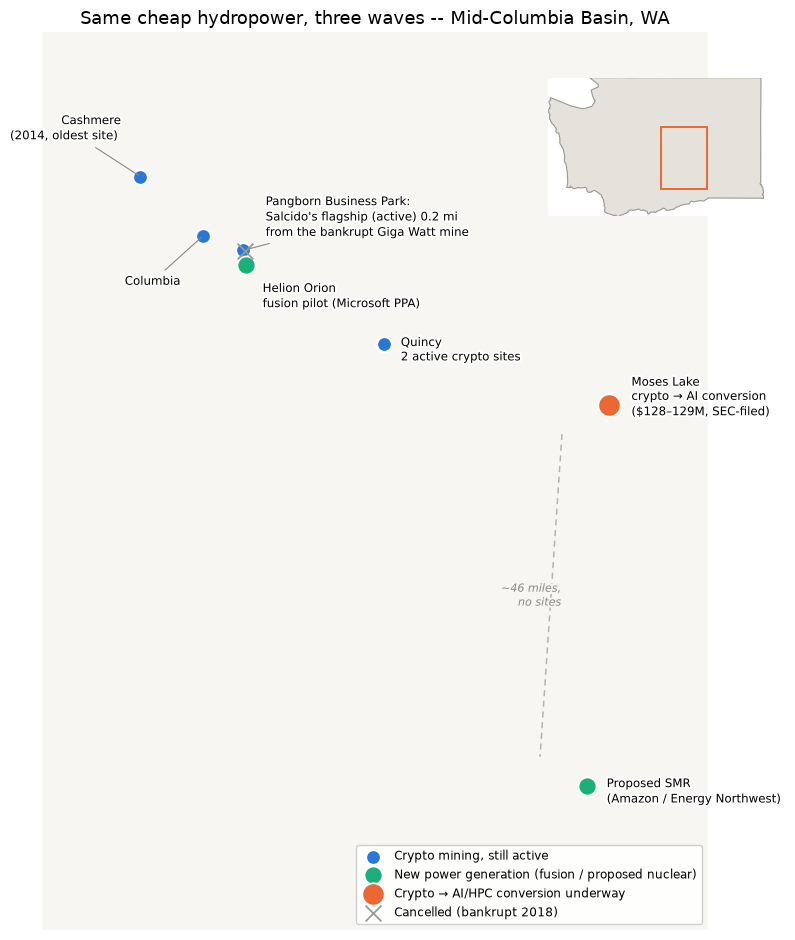

In [3]:
# Real WA state boundary for the locator inset -- same file used across this
# campaign's other WA pieces (fire-risk, grid-queue).
WA_POLY_PATH = Path("../../merascope/data/WA/raw/state.geojson")
wa_raw_feats = json.loads(WA_POLY_PATH.read_text())["features"]
wa_shape = shape(wa_raw_feats[0]["geometry"])
for f in wa_raw_feats[1:]:
    wa_shape = wa_shape.union(shape(f["geometry"]))

COLORS = {
    "crypto_active": "#2a78d6",   # categorical slot 1 (blue) -- validated all-pairs
    "crypto_to_ai": "#eb6834",    # categorical slot 2 (orange) -- the pivot, the headline
    "power_gen": "#1baf7a",       # categorical slot 3 (aqua)
    "cancelled": "#9a9a94",       # neutral gray -- historical status, not a live category
}
LABELS = {
    "crypto_active": "Crypto mining, still active",
    "crypto_to_ai": "Crypto → AI/HPC conversion underway",
    "power_gen": "New power generation (fusion / proposed nuclear)",
    "cancelled": "Cancelled (bankrupt 2018)",
}
MARKERS = {"crypto_active": "o", "crypto_to_ai": "o", "power_gen": "o", "cancelled": "x"}
SIZES = {"crypto_active": 110, "crypto_to_ai": 260, "power_gen": 170, "cancelled": 130}

lons = np.array([r["location"]["lon"] for r in sites])
lats = np.array([r["location"]["lat"] for r in sites])

def haversine_mi(lon1, lat1, lon2, lat2):
    R = 3958.8
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dp, dl = np.radians(lat2 - lat1), np.radians(lon2 - lon1)
    a = np.sin(dp / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

moses_lake = by_name["Moses Lake Facility"]["location"]
richland = by_name["Cascade Advanced Energy Facility"]["location"]
pangborn = by_name["Salcido Pangborn Data Center"]["location"]
gigawatt = by_name["Giga Watt Mining Facility (former)"]["location"]
gap_mi = haversine_mi(moses_lake["lon"], moses_lake["lat"], richland["lon"], richland["lat"])
pangborn_gigawatt_mi = haversine_mi(pangborn["lon"], pangborn["lat"], gigawatt["lon"], gigawatt["lat"])
print(f"Moses Lake to Richland: {gap_mi:.0f} miles (real gap, not a rendering artifact)")
print(f"Pangborn to Giga Watt: {pangborn_gigawatt_mi:.2f} miles (same business park, not a plotting collision)")

pad = 0.25
xmin, xmax = lons.min() - pad, lons.max() + pad
ymin, ymax = lats.min() - pad, lats.max() + pad
mean_lat = (ymin + ymax) / 2

fig, ax = plt.subplots(figsize=(9, 9.5))

for cat in ["crypto_active", "power_gen", "crypto_to_ai", "cancelled"]:
    xs = [r["location"]["lon"] for r in sites if CATEGORY[r["name"]] == cat]
    ys = [r["location"]["lat"] for r in sites if CATEGORY[r["name"]] == cat]
    ax.scatter(xs, ys, s=SIZES[cat], c=COLORS[cat], marker=MARKERS[cat],
               edgecolors="white" if MARKERS[cat] == "o" else COLORS[cat],
               linewidths=1.3, zorder=5, label=LABELS[cat])

# Direct labels. Pangborn/Giga Watt (0.2 mi apart -- same business park) get one
# combined callout instead of two colliding ones; that near-coincidence is a real
# fact worth stating, not a layout problem to paper over. Cashmere and Columbia
# get short leader lines since their labels can't sit close to the marker without
# colliding with the Pangborn callout.
cashmere = by_name["Salcido Cashmere Data Center"]["location"]
columbia = by_name["Salcido Columbia Data Center"]["location"]
ax.annotate("Cashmere\n(2014, oldest site)", (cashmere["lon"], cashmere["lat"]),
            textcoords="offset points", xytext=(-14, 24), fontsize=8.5, ha="right", va="bottom",
            arrowprops=dict(arrowstyle="-", color="#8a887f", linewidth=0.8),
            path_effects=[pe.withStroke(linewidth=3, foreground="white")], zorder=6)
ax.annotate("Columbia", (columbia["lon"], columbia["lat"]),
            textcoords="offset points", xytext=(-16, -28), fontsize=8.5, ha="right", va="top",
            arrowprops=dict(arrowstyle="-", color="#8a887f", linewidth=0.8),
            path_effects=[pe.withStroke(linewidth=3, foreground="white")], zorder=6)

callouts = {
    "Helion Orion fusion power plant": ("Helion Orion\nfusion pilot (Microsoft PPA)", (12, -22)),
    "Moses Lake Facility": ("Moses Lake\ncrypto → AI conversion\n($128–129M, SEC-filed)", (16, 6)),
    "Cascade Advanced Energy Facility": ("Proposed SMR\n(Amazon / Energy Northwest)", (14, -4)),
}
for r in sites:
    if r["name"] in callouts:
        text, offset = callouts[r["name"]]
        ax.annotate(text, (r["location"]["lon"], r["location"]["lat"]),
                    textcoords="offset points", xytext=offset, fontsize=8.5,
                    ha="left" if offset[0] >= 0 else "right", va="center",
                    path_effects=[pe.withStroke(linewidth=3, foreground="white")], zorder=6)
ax.annotate(f"Pangborn Business Park:\nSalcido's flagship (active) {pangborn_gigawatt_mi:.1f} mi\nfrom the bankrupt Giga Watt mine",
            (pangborn["lon"], pangborn["lat"]), textcoords="offset points", xytext=(16, 24),
            fontsize=8.5, ha="left", va="center",
            arrowprops=dict(arrowstyle="-", color="#8a887f", linewidth=0.8),
            path_effects=[pe.withStroke(linewidth=3, foreground="white")], zorder=6)
ax.annotate("Quincy\n2 active crypto sites", (-119.857, 47.235),
            textcoords="offset points", xytext=(14, -4), fontsize=8.5, ha="left", va="center",
            path_effects=[pe.withStroke(linewidth=3, foreground="white")], zorder=6)

# Turn the real Moses-Lake-to-Richland gap into a labeled distance instead of
# dead space.
ax.plot([moses_lake["lon"] - 0.12, richland["lon"] - 0.12], [moses_lake["lat"] - 0.05, richland["lat"] + 0.05],
        linestyle=(0, (4, 3)), color="#b5b3aa", linewidth=1.1, zorder=2)
ax.annotate(f"~{gap_mi:.0f} miles,\nno sites", (moses_lake["lon"] - 0.12, (moses_lake["lat"] + richland["lat"]) / 2),
            fontsize=8, color="#8a887f", ha="right", va="center", style="italic",
            path_effects=[pe.withStroke(linewidth=3, foreground="#f7f6f2")], zorder=2)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect(1 / np.cos(np.radians(mean_lat)))
ax.set_xticks([]); ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_facecolor("#f7f6f2")

ax.legend(loc="lower right", fontsize=8.5, frameon=True, facecolor="white", framealpha=0.92)
ax.set_title("Same cheap hydropower, three waves -- Mid-Columbia Basin, WA", fontsize=13)

# Locator inset: WA outline with the corridor's extent boxed, tucked in the
# empty top-right corner (nothing plotted there, so no collision with the map).
inset = fig.add_axes([0.68, 0.72, 0.24, 0.24])
wa_parts = wa_shape.geoms if wa_shape.geom_type == "MultiPolygon" else [wa_shape]
for part in wa_parts:
    xs, ys = part.exterior.xy
    inset.fill(xs, ys, facecolor="#e4e2da", edgecolor="#9a9a94", linewidth=0.8)
inset.add_patch(Rectangle((xmin, ymin), xmax - xmin, ymax - ymin,
                           facecolor="none", edgecolor=COLORS["crypto_to_ai"], linewidth=1.4))
wb = wa_shape.bounds
inset.set_xlim(wb[0], wb[2]); inset.set_ylim(wb[1], wb[3])
inset.set_aspect(1 / np.cos(np.radians((wb[1] + wb[3]) / 2)))
inset.set_xticks([]); inset.set_yticks([])
for spine in inset.spines.values():
    spine.set_visible(False)

fig.tight_layout()
fig.savefig("mid_columbia_map.png", dpi=150, bbox_inches="tight")
plt.show()

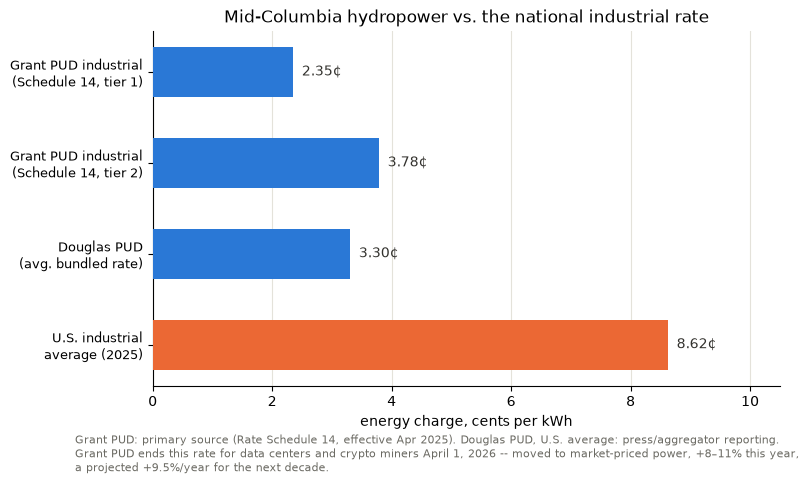

In [4]:
# Rate comparison. Grant PUD figures are a real primary source -- Rate Schedule
# No. 14 (Industrial Service), fetched directly from grantpud.org, effective
# April 1 2025: $0.02346/kWh for the first 7.3M kWh/month, $0.03783/kWh above
# that, plus a $5.96/kW demand charge (not shown -- this chart is energy charge
# only, the number a national-average industrial comparison actually maps to).
# Douglas PUD and the US industrial average are secondary -- press/aggregator
# reporting, not a primary tariff pulled here -- flagged as such in the caption.
bars = [
    ("Grant PUD industrial\n(Schedule 14, tier 1)", 2.346, "pnw"),
    ("Grant PUD industrial\n(Schedule 14, tier 2)", 3.783, "pnw"),
    ("Douglas PUD\n(avg. bundled rate)", 3.3, "pnw"),
    ("U.S. industrial\naverage (2025)", 8.62, "national"),
]
COLOR2 = {"pnw": "#2a78d6", "national": "#eb6834"}

fig, ax = plt.subplots(figsize=(8, 4.5))
ys = np.arange(len(bars))[::-1]
for y, (label, val, grp) in zip(ys, bars):
    ax.barh(y, val, color=COLOR2[grp], height=0.55, zorder=3)
    ax.text(val + 0.15, y, f"{val:.2f}\u00a2", va="center", fontsize=10, color="#33322e")
ax.set_yticks(ys)
ax.set_yticklabels([b[0] for b in bars], fontsize=9.5)
ax.set_xlabel("energy charge, cents per kWh")
ax.set_xlim(0, 10.5)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
ax.grid(axis="x", color="#e4e2da", linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
ax.set_title("Mid-Columbia hydropower vs. the national industrial rate", fontsize=12.5)

fig.text(0.1, -0.06,
         "Grant PUD: primary source (Rate Schedule 14, effective Apr 2025). Douglas PUD, U.S. average: press/aggregator reporting.\n"
         "Grant PUD ends this rate for data centers and crypto miners April 1, 2026 -- moved to market-priced power, +8\u201311% this year,\n"
         "a projected +9.5%/year for the next decade.",
         fontsize=8, color="#6b6a63")

fig.tight_layout()
fig.savefig("mid_columbia_rates.png", dpi=150, bbox_inches="tight")
plt.show()

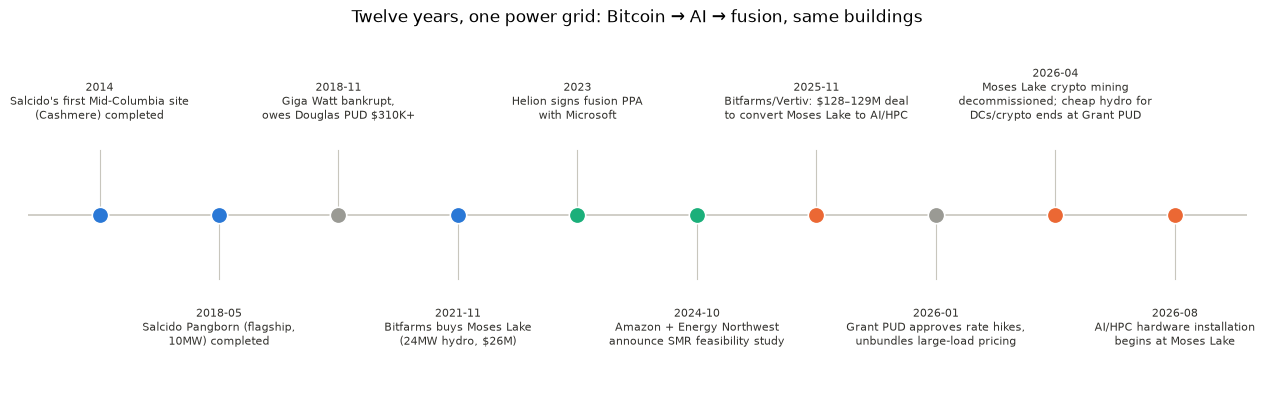

In [5]:
# Timeline strip -- every date sourced to the record it came from (see the
# per-site notes/statusHistory pulled in the first cell; not re-derived here).
events = [
    ("2014", "Salcido's first Mid-Columbia site\n(Cashmere) completed", "crypto_active"),
    ("2018-05", "Salcido Pangborn (flagship,\n10MW) completed", "crypto_active"),
    ("2018-11", "Giga Watt bankrupt,\nowes Douglas PUD $310K+", "cancelled"),
    ("2021-11", "Bitfarms buys Moses Lake\n(24MW hydro, $26M)", "crypto_active"),
    ("2023", "Helion signs fusion PPA\nwith Microsoft", "power_gen"),
    ("2024-10", "Amazon + Energy Northwest\nannounce SMR feasibility study", "power_gen"),
    ("2025-11", "Bitfarms/Vertiv: $128\u2013129M deal\nto convert Moses Lake to AI/HPC", "crypto_to_ai"),
    ("2026-01", "Grant PUD approves rate hikes,\nunbundles large-load pricing", "cancelled"),
    ("2026-04", "Moses Lake crypto mining\ndecommissioned; cheap hydro for\nDCs/crypto ends at Grant PUD", "crypto_to_ai"),
    ("2026-08", "AI/HPC hardware installation\nbegins at Moses Lake", "crypto_to_ai"),
]

fig, ax = plt.subplots(figsize=(13, 4.2))
xs = np.arange(len(events))
ax.axhline(0, color="#c8c6bd", linewidth=1.2, zorder=1)

for i, (date, text, cat) in enumerate(events):
    ax.scatter(i, 0, s=140, c=COLORS[cat], zorder=3, edgecolors="white", linewidths=1.2)
    above = i % 2 == 0
    y_text = 0.55 if above else -0.55
    va = "bottom" if above else "top"
    ax.plot([i, i], [0, y_text * 0.7], color="#c8c6bd", linewidth=0.8, zorder=2)
    ax.text(i, y_text, f"{date}\n{text}", ha="center", va=va, fontsize=8.2, color="#33322e")

ax.set_xlim(-0.6, len(events) - 0.4)
ax.set_ylim(-1.1, 1.1)
ax.set_xticks([]); ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title("Twelve years, one power grid: Bitcoin \u2192 AI \u2192 fusion, same buildings", fontsize=12.5)

fig.tight_layout()
fig.savefig("mid_columbia_timeline.png", dpi=150, bbox_inches="tight")
plt.show()

## Notes for the caption

- **Every site's coordinates and dates come straight from Compute Atlas's own per-record file**, matched by name (assert above fails loudly if any go missing), not hand-copied into this notebook disconnected from source.
- **The Moses Lake conversion is SEC-filed, not a press release gloss**: Bitfarms' (now "Keel Infrastructure") own 10-K and 8-Ks disclose the $128–129M Vertiv deal, the NVIDIA GB300 target hardware, and the April 2026 decommissioning date. `aiClassification` on that record is "likely," not "confirmed" -- no GPUs were operating as of the most recent filing at the time Compute Atlas retrieved it (Aug 2026).
- **Rate numbers are mixed-provenance, on purpose, and labeled as such**: Grant PUD's Schedule 14 is a primary document (fetched directly this session). Douglas PUD's average and the US industrial average are press/aggregator figures, not independently re-derived from EIA's raw tables -- caption should not claim more precision than that.
- **"Ends April 1, 2026" is Grant PUD's own stated effective date** for unbundling large loads onto market-priced power, per its own commission recap; the +8-11%/+9.5%-projected figures are secondary reporting on that same policy, not a number pulled from a rate schedule PDF directly.
- **Two different named companies, same site, no relation**: Salcido's Pangborn Data Center (still operating) and the defunct Giga Watt mine are separate parcels in the same Pangborn Business Park -- do not conflate them in the caption.